<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_WEEK_12_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<코드 수정사항>

코드 실행 시 런타임 유형 GPU로 변경 후 실행


1) 8-4
images, labels = dataiter.next()
>> 수정
images, labels = next(dataiter)

2) 8-26
```
args = vars(parser.parse_args())
```
>> 수정

args, unknown = parser.parse_known_args()
args = vars(args)

딥러닝 파이토치 교과서 ch8. p.461~504

# Chapter 08. 성능 최적화

## 03. 하이퍼파라미터를 이용한 성능 최적화

하이퍼파라미터를 이용한 성능 최적화의 추가적인 방법으로 배치 정규화, 드롭아웃, 조기 종료가 있음


### 1) 배치 정규화를 이용한 성능 최적화

**정규화**

정규화(normalization): 데이터 범위를 사용자가 원하는 범위로 제한하는 것을 의미

<img src="https://drive.google.com/uc?export=view&id=1SD5ZkC5354aIh4-gXidxnZjSOcdiHijN" width="500">

정규화는 각 특성 범위(스케일(scale))를 조정한다는 의미로 특성 스케일링(feature scaling)이라고도 함. 스케일 조정을 위해 MinMaxScaler() 기법을 사용하므로 수식은 다음과 같음

<img src="https://drive.google.com/uc?export=view&id=1TgLIH1pczazqXuzegKnc5MSG0ViERL2z" width="110">


**규제화**

규제화(regularization)는 모델 복잡도를 줄이기 위해 제약을 두는 방법. 이때 제약은 데이터가 네트워크에 들어가기 전에 필터를 적용한 것이라고 생각하면 됨.

<img src="https://drive.google.com/uc?export=view&id=18TDeqMg_6PoY4VDOb3HFGPQ5bhf7_OaB" width="400">

규제를 이용하여 모델 복잡도를 줄이는 방법은 다음과 같음

- 드롭아웃
- 조기종료


**표준화**

표준화(standardization): 기존 데이터를 평균은 0, 표준편차는 1인 형태의 데이터로 만드는 방법

다른 표현으로 표준화 스칼라(standard scaler) 혹은 z-스코어 정규화(z-score normalization)
라고도 함

<img src="https://drive.google.com/uc?export=view&id=1ZuJiwtd_HioA-kNPIZHGN6Cn3AreklRJ" width="200">

평균을 기준으로 얼마나 떨어져 있는지 살펴볼 때 사용. 보통 데이터 분포가 가우시안 분포를 따를 때 유용한 방법으로 다음 수식을 사용

<img src="https://drive.google.com/uc?export=view&id=1pH62UxVed2mfmSb30h0q3w28ogBGa82q" width="250">


**배치 정규화**

배치 정규화(batch normaJization)

- 2015년 "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift" 논문에 설명되어 있는 기법, 데이터 분포가 안정되어 학습 속도를 높일 수 있음
- 기울기 소멸 (gradient vanishing)이나 기울기 폭발(gradient exploding) 같은 문제를 해결하기 위한 방법
- 일반적으로 기울기 소멸이나 폭발 문제를 해결하기 위해 손실 함수로 렐루를 사용하거나 초깃값 튜닝, 학습률 등을 조정

<img src="https://drive.google.com/uc?export=view&id=1kbd3PII_kzb2T2g5jgeB07F1Rg1Piodh" width="400">

배치 정규화가 소개도니 논문에 따르면 기울기 소멸과 폭발 원인은 내부 공변량 변화 때문, 이것은 네트워크의 각 층마다 활성화 함수가 적용되면서 입력 값들의 분포가 계속 바뀌는 현상을 의미.

따라서 분산된 분포를 정규분포로 만들기 위해 표준화와 유사한 방식을 미니 배치(mini-batch)에 적용하여 평균은 0으로, 표준편차는 1로 유지하도록 하며 수식은 다음과 같음

<img src="https://drive.google.com/uc?export=view&id=1Vs7QOHlD9ls6c1vF3lbBGpoPYWVyq8EJ" width="200">

1) 미니 배치 평균을 구함
2) 미니 배치의 분산과 표준편차를 구함
3) 정규화를 수행
4) 스케일을 조정(데이터 분포 조정)


### 2) 드롭아웃을 이용한 성능 최적화

과적합은 훈련 데이터셋을 과하게 학습하는 것을 의미

훈련 데이터셋에 대해 훈련을 계속한다면 오류는 줄어들지만 테스트 데이터셋에 대한 오류는 어느 순간부터 증가하는데 이러한 모델을 과적합되어 있다고 함

<img src="https://drive.google.com/uc?export=view&id=1ok6spHvNkZryyaDBqbVWz3TkxAzH21As" width="250">

드롭아웃(dropout)
- 훈련할 때 일정 비율의 뉴런만 사용하고 나머지 뉴런에 해당하는 가중치는 업데이트하지 않는 방법
- 노드를 임의로 끄면서 학습하는 방법
- 은닉층에 배치된 노드 중 일부를
임의로 끄면서 학습
- 꺼진 노드는 신호를 전달하지 않으므로 지나친 학습을 방지하는 효과가 생김

<img src="https://drive.google.com/uc?export=view&id=1ZO-Paeko0B1qZe9gNwNo_Xt5UvD1RS-c" width="400">

그림 8-37의 왼쪽은 일반적인 신경망이고 오른쪽은 드롭아웃이 적용된 신경망의 모습

드롭아웃을 사용하면 훈련 시간이 길어지는 단점이 있지만, 모델 성능을 향상하기 위해 상당히 자주 쓰는 방법






In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

In [2]:
trainset = torchvision.datasets.FashionMNIST(
    root = './data',
    train = True,
    download = True,
    transform = transforms.ToTensor()
)

In [3]:
batch_size = 4
trainloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True)

In [4]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

print(images.shape)
print(images[0].shape)
print(labels[0].item())

torch.Size([4, 1, 28, 28])
torch.Size([1, 28, 28])
6


In [5]:
def imshow(img, title):
    plt.figure(figsize = (batch_size * 4, 4))
    plt.axis('off')
    plt.imshow(np.transpose(img, (1, 2, 0)))
    plt.title(title)
    plt.show()

In [6]:
def show_batch_images(dataloader):
  images, labels = next(iter(dataloader))

  img = torchvision.utils.make_grid(images)
  imshow(img, title=[str(x.item()) for x in labels])

  return images, labels

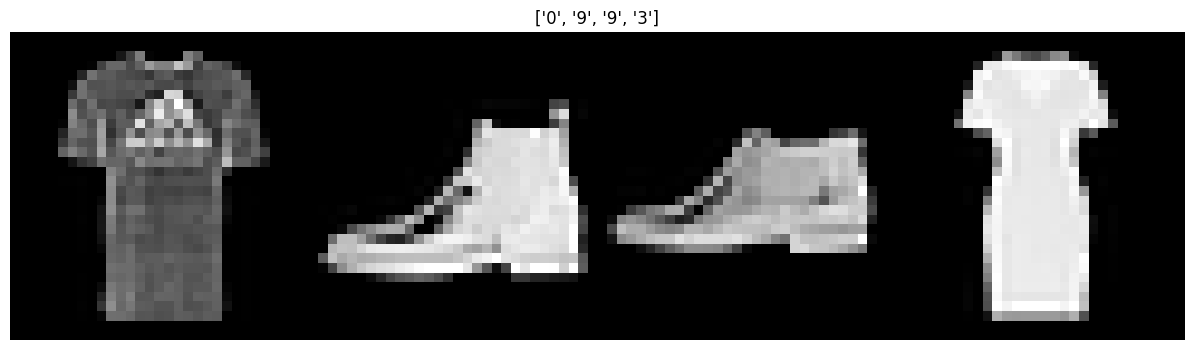

In [7]:
images, labels = show_batch_images(trainloader)

In [8]:
class NormalNet(nn.Module):
  def __init__(self):
    super(NormalNet, self).__init__()
    self.classifier = nn.Sequential(
        nn.Linear(784, 48),
        nn.ReLU(),
        nn.Linear(48, 24),
        nn.ReLU(),
        nn.Linear(24, 10)
    )

  def forward(self, x):
    x = x.view(x.size(0), -1)
    x = self.classifier(x)
    return x

In [9]:
class BNNet(nn.Module):
  def __init__(self):
    super(BNNet, self).__init__()
    self.classifier = nn.Sequential(
        nn.Linear(784, 48),
        nn.BatchNorm1d(48),
        nn.ReLU(),
        nn.Linear(48, 24),
        nn.BatchNorm1d(24),
        nn.ReLU(),
        nn.Linear(24, 10)
    )

  def forward(self, x):
    x = x.view(x.size(0), -1)
    x = self.classifier(x)
    return x

(1) 배치 정규화가 적용되는 부분. BatchNorm1d에서 사용되는 파라미터는 특성 개수로 이전 계층의 출력 채널이 됨

신경망의 층이 갚어질수록 학습할 때 가정했던 입력 분포가 변화하여 엉뚱한 학습이 진행될 수 있는데 **배치 정규화**를 적용해서 입력 분포를 고르게 맞추어 줄 수 있음

<img src="https://drive.google.com/uc?export=view&id=111nHXls4wfnyTZsusTg1TH0plDxWRGIi" width="350">


참고로 배치 정규화는 다음과 같은 위치에 놓여야 함

<img src="https://drive.google.com/uc?export=view&id=1fdI6UHurlYpdMRIYKnt-yK1OTX9m1-K8" width="300">

In [10]:
model = NormalNet()
print(model)

NormalNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): ReLU()
    (2): Linear(in_features=48, out_features=24, bias=True)
    (3): ReLU()
    (4): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [11]:
model_bn = BNNet()
print(model_bn)

BNNet(
  (classifier): Sequential(
    (0): Linear(in_features=784, out_features=48, bias=True)
    (1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=48, out_features=24, bias=True)
    (4): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=24, out_features=10, bias=True)
  )
)


In [12]:
batch_size = 512
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)

In [13]:
loss_fn = nn.CrossEntropyLoss()
opt = optim.SGD(model.parameters(), lr=0.01)
opt_bn = optim.SGD(model_bn.parameters(), lr=0.01)

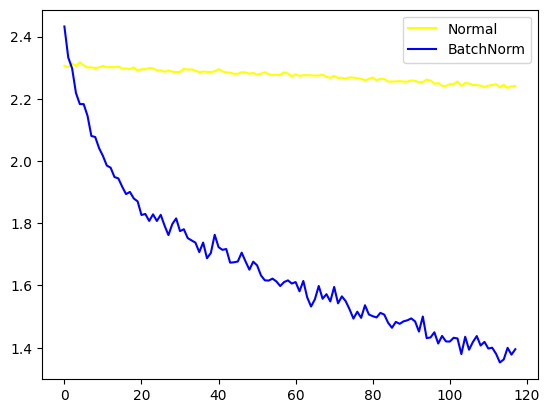

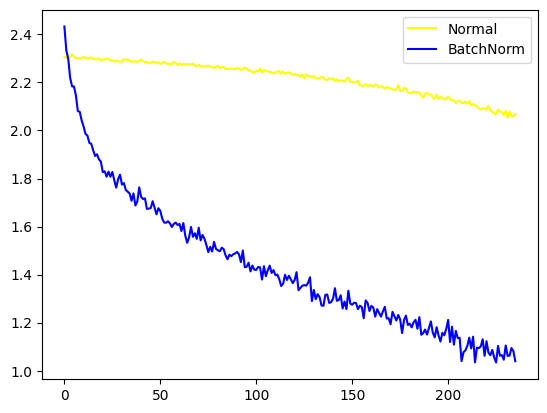

In [14]:
loss_arr = []
loss_bn_arr = []
max_epochs = 2

for epoch in range(max_epochs):
  for i, data in enumerate(trainloader, 0):
    inputs, labels = data
    opt.zero_grad() # 배치 정규화가 적용되지 않은 모델의 학습
    outputs = model(inputs)
    loss = loss_fn(outputs, labels)
    loss.backward()
    opt.step()

    opt_bn.zero_grad() # 배치 정규화가 적용된 모델의 학습
    outputs_bn = model_bn(inputs)
    loss_bn = loss_fn(outputs_bn, labels)
    loss_bn.backward()
    opt_bn.step()

    loss_arr.append(loss.item())
    loss_bn_arr.append(loss_bn.item())

  plt.plot(loss_arr, 'yellow', label='Normal')
  plt.plot(loss_bn_arr, 'blue', label='BatchNorm')
  plt.legend()
  plt.show()

In [15]:
N = 50
noise = 0.3

x_train = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
y_train = x_train + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

x_test = torch.unsqueeze(torch.linspace(-1, 1, N), 1)
y_test = x_test + noise * torch.normal(torch.zeros(N, 1), torch.ones(N, 1))

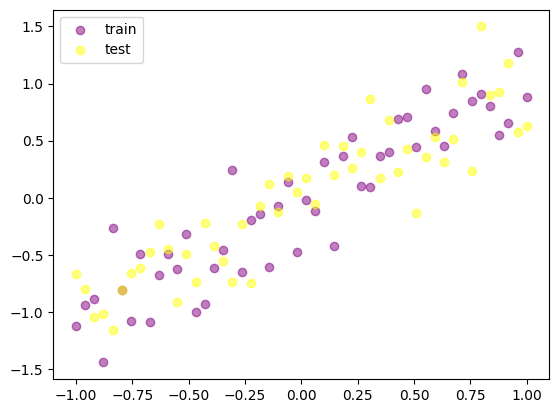

In [16]:
plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c = 'purple',
            alpha = 0.5, label = 'train')
plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c = 'yellow',
            alpha = 0.5, label = 'test')
plt.legend()
plt.show()

In [17]:
N_h = 100
model = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.ReLU(),
    torch.nn.Dropout(p = 0.5),
    torch.nn.Linear(N_h, 1),
) # 드롭아웃이 적용되지 않은 모델

model_dropout = torch.nn.Sequential(
    torch.nn.Linear(1, N_h),
    torch.nn.Dropout(0.2), # 드롭아웃 적용
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, N_h),
    torch.nn.Dropout(0.2),
    torch.nn.ReLU(),
    torch.nn.Linear(N_h, 1),
) # 드롭아웃이 적용된 모델

In [18]:
opt = torch.optim.Adam(model.parameters(), lr = 0.01)
opt_dropout = torch.optim.Adam(model_dropout.parameters(), lr = 0.01)
loss_fn = torch.nn.MSELoss()

/tmp/ipykernel_19528/4250749121.py:31: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' %


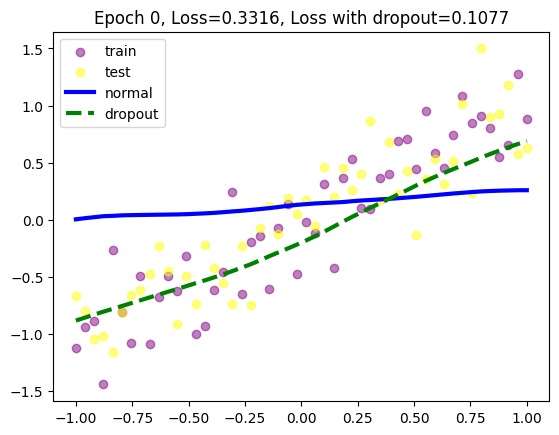

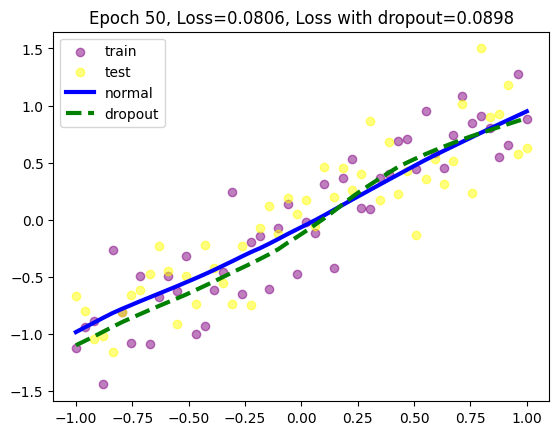

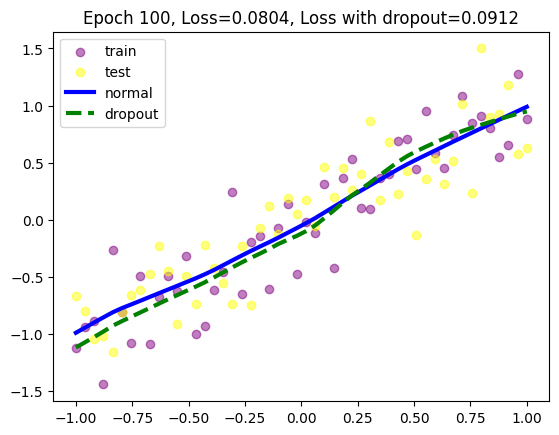

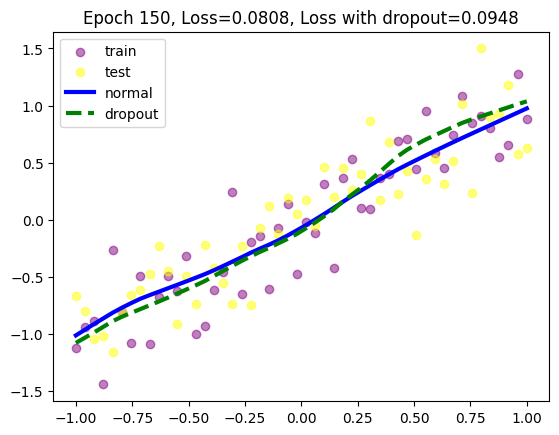

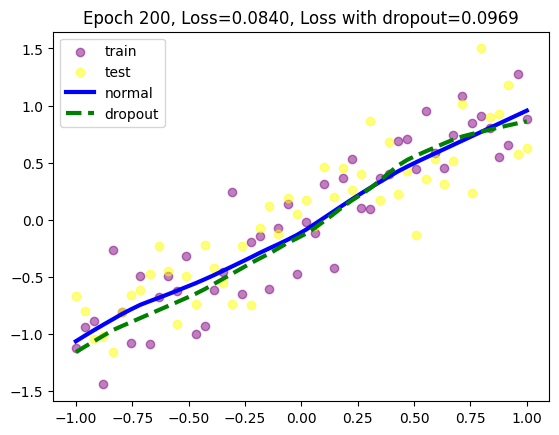

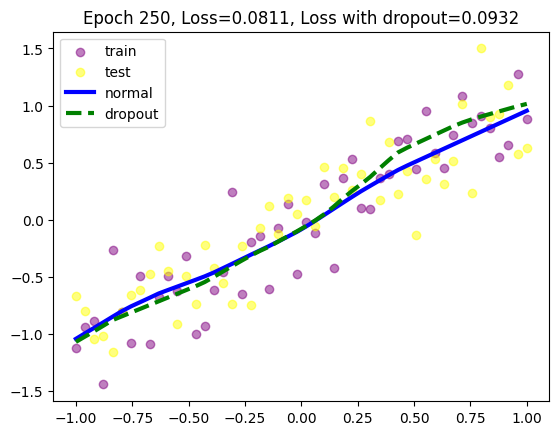

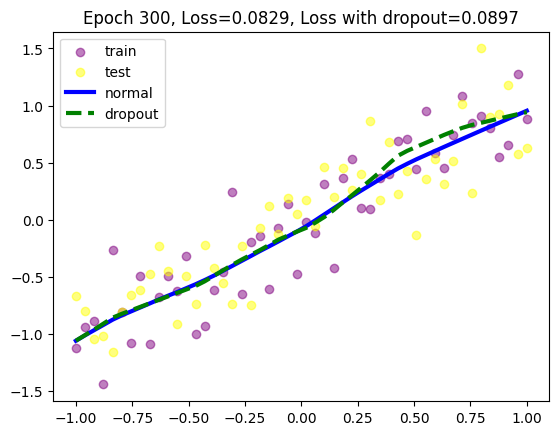

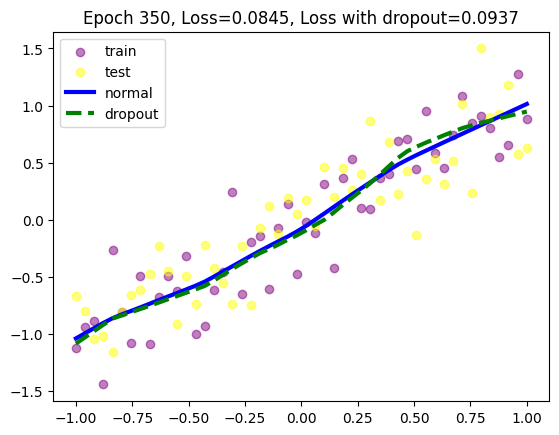

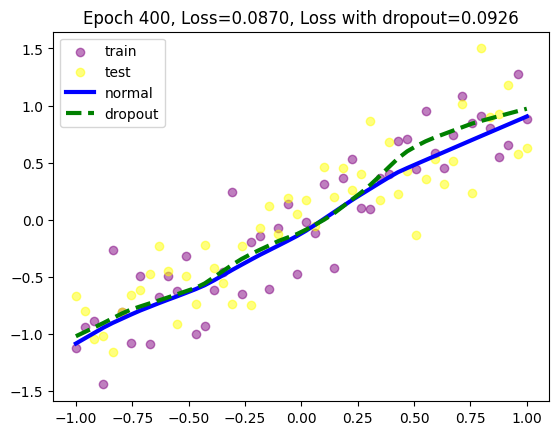

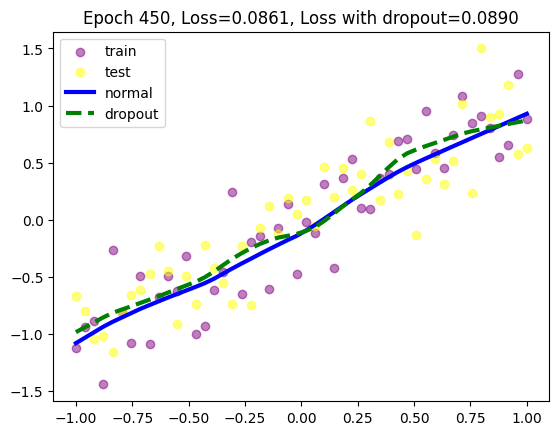

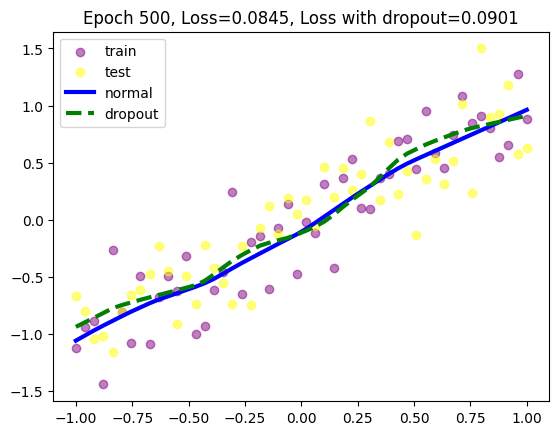

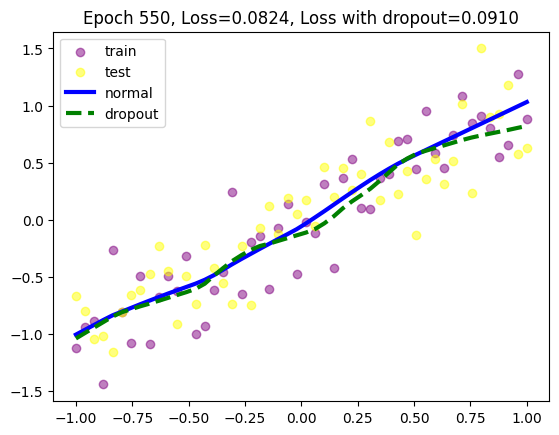

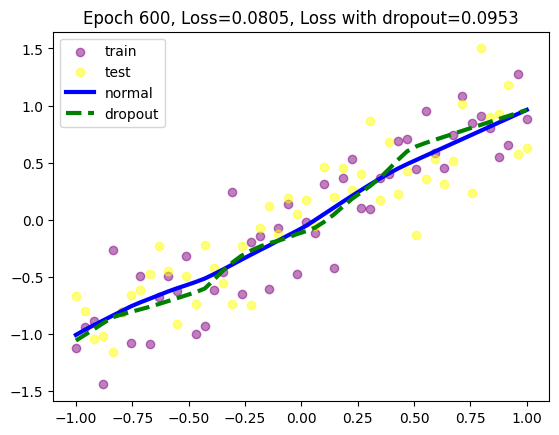

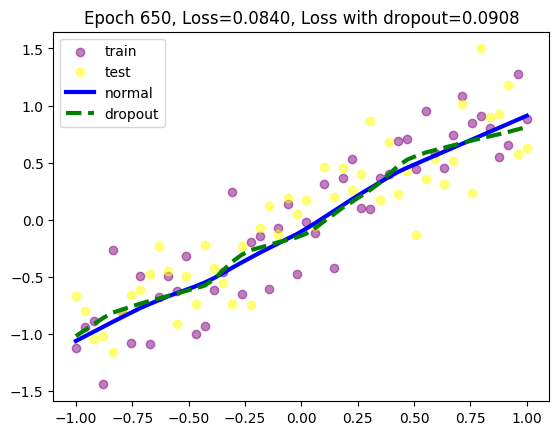

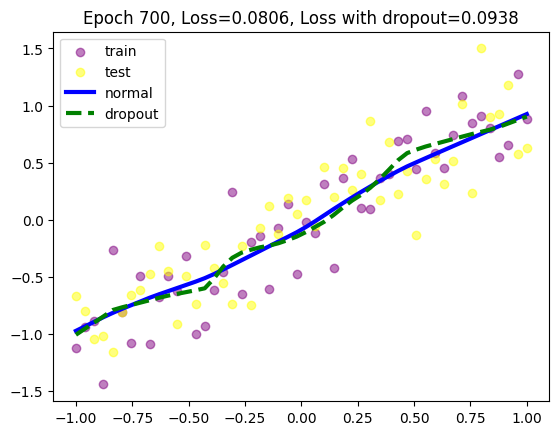

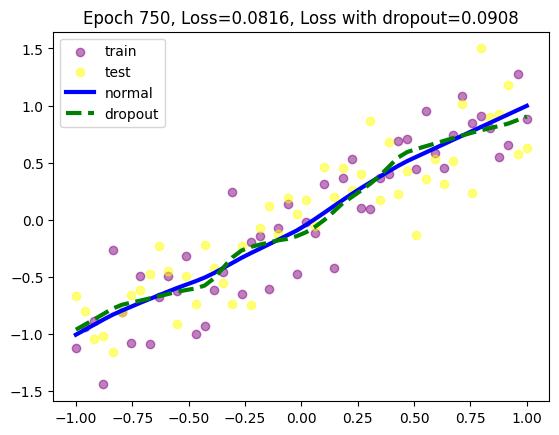

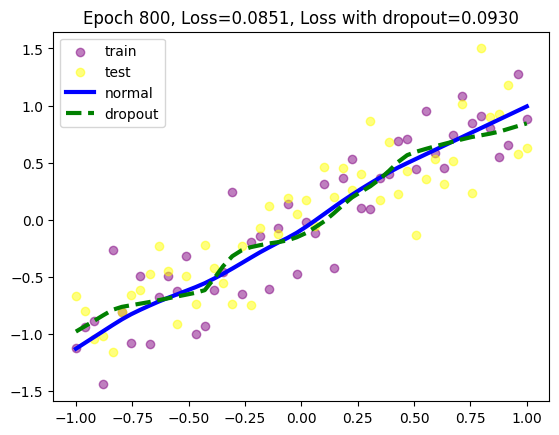

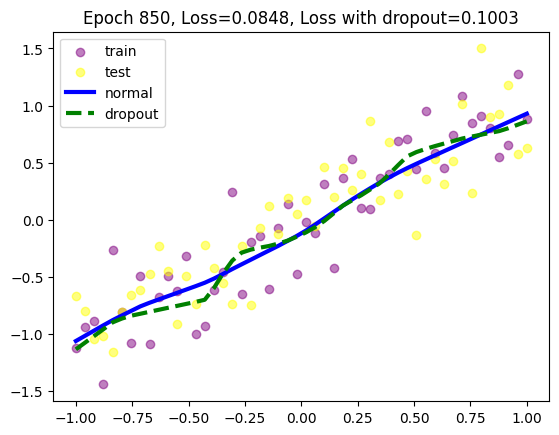

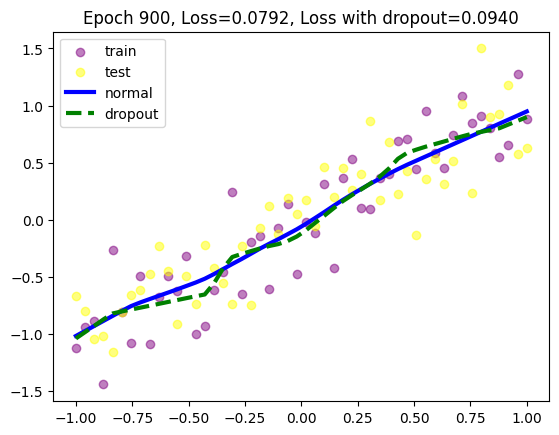

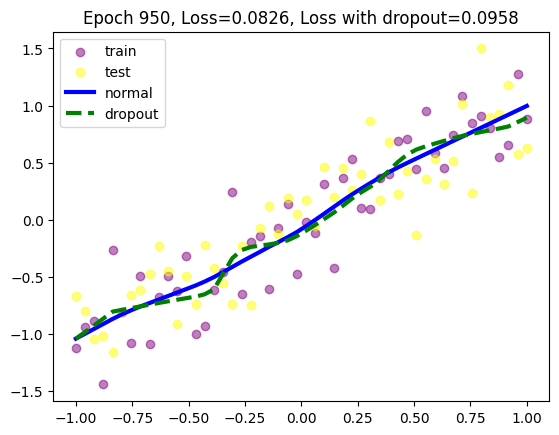

In [19]:
max_epochs = 1000
for epoch in range(max_epochs):
  pred = model(x_train) # 드롭아웃이 적용되지 않은 모델 학습
  loss = loss_fn(pred, y_train)
  opt.zero_grad()
  loss.backward()
  opt.step()

  pred_dropout = model_dropout(x_train) # 드롭아웃이 적용된 모델 학습
  loss_dropout = loss_fn(pred_dropout, y_train)
  opt_dropout.zero_grad()
  loss_dropout.backward()
  opt_dropout.step()

  if epoch % 50 == 0:
    model.eval()
    model_dropout.eval()

    test_pred = model(x_test)
    test_loss = loss_fn(test_pred, y_test)

    test_pred_dropout = model_dropout(x_test)
    test_loss_dropout = loss_fn(test_pred_dropout, y_test)

    plt.scatter(x_train.data.numpy(), y_train.data.numpy(), c='purple',
                alpha=0.5, label='train')
    plt.scatter(x_test.data.numpy(), y_test.data.numpy(), c='yellow',
                alpha=0.5, label='test')
    plt.plot(x_test.data.numpy(), test_pred.data.numpy(), 'b-', lw=3, label='normal')
    plt.plot(x_test.data.numpy(), test_pred_dropout.data.numpy(), 'g--', lw=3, label='dropout')
    plt.title('Epoch %d, Loss=%0.4f, Loss with dropout=%0.4f' %
              (epoch, test_loss, test_loss_dropout))
    plt.legend()
    model.train()
    model_dropout.train()
    plt.pause(0.05)

### 3) 조기 종료를 이용한 성능 최적화


<img src="https://drive.google.com/uc?export=view&id=1v9qOechIqM1W505yLMzSVkn3kdYkPWKb" width="300">

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torchvision import transforms, datasets

import matplotlib
import matplotlib.pyplot as plt
import time
import argparse
from tqdm import tqdm
matplotlib.style.use('ggplot')
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [21]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [22]:
!git clone https://github.com/gilbutITbook/080289.git

fatal: destination path '080289' already exists and is not an empty directory.


In [23]:
train_dataset = datasets.ImageFolder(
    root=r'/content/080289/chap08/data/archive/train', # Changed from .csv to directory
    transform = train_transform
)
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size = 32, shuffle = True,
)
val_dataset = datasets.ImageFolder(
    root =r'/content/080289/chap08/data/archive/test', # Changed from .csv to directory
    transform = val_transform
)
val_dataloader = torch.utils.data.DataLoader(
    val_dataset, batch_size = 32, shuffle = False,
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/080289/chap08/data/archive/train'